# Import

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

In [40]:
# Read the COBRA output file
with open('PWR_INP_2_2.txt.out', 'r') as file:
    lines = file.readlines()

# Find the beginning of the temperature data section
start = next(
    i for i, line in enumerate(lines)
    if 'TEMPERATURE DATA FOR ROD' in line
)

# Extract the numerical data
data = []

for line in lines[start+1:]:
    values = line.split()

    if len(values) >= 3:
        try:
            distance = float(values[0])
            dnbr = float(values[2])
            data.append([distance, dnbr])
        except ValueError:
            # Stop once we reach the end of the data table
            if data:
                break

# Convert into NumPy arrays
data = np.array(data)

distance = data[:, 0]
dnbr = data[:, 1]

distance = distance[4:]
dnbr = dnbr[4:]

print("Distance:", distance)
print("DNBR:", dnbr)
print("MDNBR:", np.min(dnbr))

Distance: [0.9 1.1 1.3 1.5 1.7 1.9 2.1 2.3 2.5 2.7 2.9 3.1 3.3 3.5]
DNBR: [7.779 6.187 5.146 4.43  3.924 3.56  3.3   3.118 3.    2.936 2.923 2.958
 3.045 3.19 ]
MDNBR: 2.923


In [26]:
data_1_1 = np.load("PWR_INP_1_1.txt_temperature_arrays.npz")

data_2_2 = np.load("PWR_INP_2_2.txt_temperature_arrays.npz")

z_coordinates_1_1 = data_1_1["z_coordinates"]
coolant_temperature_1_1 = data_1_1["coolant_temperature"]

z_coordinates_2_2 = data_2_2["z_coordinates"]
coolant_temperature_2_2 = data_2_2["coolant_temperature"]

print(z_coordinates_1_1)
print(coolant_temperature_1_1)
print(z_coordinates_2_2)
print(coolant_temperature_2_2)

[0.1 0.3 0.5 0.7 0.9 1.1 1.3 1.5 1.7 1.9 2.1 2.3 2.5 2.7 2.9 3.1 3.3 3.5]
[563.24 563.96 565.12 566.7  568.63 570.85 573.28 575.86 578.49 581.1
 583.61 585.95 588.06 589.88 591.38 592.5  593.24 593.57]
[0.1 0.3 0.5 0.7 0.9 1.1 1.3 1.5 1.7 1.9 2.1 2.3 2.5 2.7 2.9 3.1 3.3 3.5]
[563.24 563.96 565.12 566.7  568.63 570.85 573.28 575.86 578.49 581.1
 583.61 585.95 588.06 589.88 591.38 592.5  593.24 593.57]


# Plotting

In [43]:
# prep
from matplotlib.lines import Line2D
from matplotlib.colors import to_rgba
from matplotlib.legend_handler import HandlerTuple


plt.rcParams.update({
    "font.size": 14,  # default text size
    "axes.titlesize": 16,  # title size
    "axes.labelsize": 15,  # axis labels
    "legend.fontsize": 11,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12
})

plt.rcParams.update({
    "font.family": "Times New Roman",  # Use Times New Roman for all text
    "mathtext.fontset": "custom",  # Use custom font for math
    "mathtext.rm": "Times New Roman",  # Roman font in math
    "mathtext.it": "Times New Roman:italic",  # Italic font in math
    "mathtext.bf": "Times New Roman:bold",  # Bold font in math
    "text.usetex": False
})

primary_color = "black"

color_list = ["#D55E00", "#0072B2"]
marker_list = ["o", "D"]
labels = [
    r"$D_{\mathrm{rod}} = 9.5\ \mathrm{mm}$",
    r"$D_{\mathrm{rod}} = 11\ \mathrm{mm}$"
]

legend_elements = []

for color, marker, label in zip(color_list, marker_list, labels):

    line = Line2D(
        [0], [0],
        color=to_rgba(color, 0.3),
        linestyle='--',
        linewidth=1.5
    )

    marker_handle = Line2D(
        [0], [0],
        color=color,
        marker=marker,
        linestyle='None',
        markerfacecolor='none',
        markeredgecolor=color,
        markersize=5
    )

    legend_elements.append(((line, marker_handle), label))

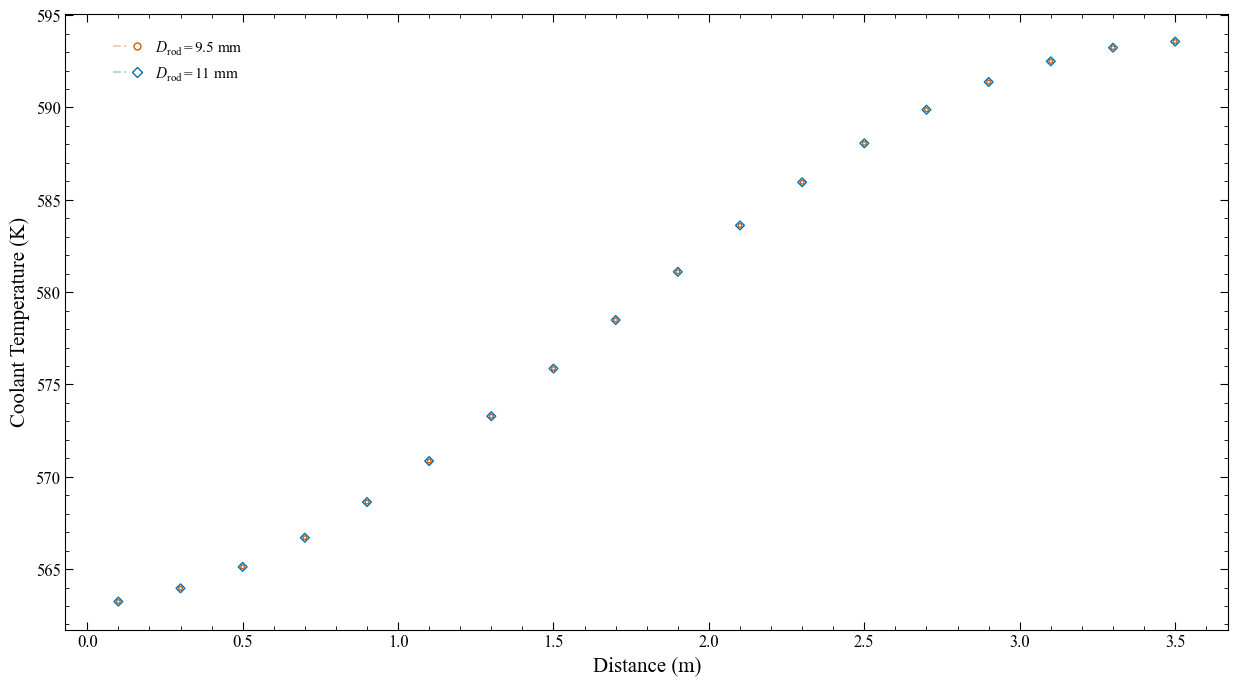

In [44]:
fig = plt.figure(figsize=(15, 8))

gs = fig.add_gridspec(
    1, 1,
    hspace=0
)

ax_main = fig.add_subplot(gs[0])


###########
# Main Axis
###########

for xdata, ydata, markers, color, sizes in zip([z_coordinates_1_1, z_coordinates_2_2],[coolant_temperature_1_1, coolant_temperature_2_2],
                                        marker_list,color_list, [7,20]):
    ax_main.scatter(xdata, ydata,
                marker=markers, color=color, s=sizes, facecolor="none")


ax_main.legend(
    handles=[item[0] for item in legend_elements],
    labels=[item[1] for item in legend_elements],
    handler_map={tuple: HandlerTuple(ndivide=None)},
    loc="upper left",
    bbox_to_anchor=(0.03, 0.98),
    borderpad=0.3,
    facecolor="white",
    edgecolor="white",
    framealpha=1
)

#####################
# Formatting and Save
#####################

ax_main.set_xlabel("Distance (m)")
ax_main.set_ylabel("Coolant Temperature (K)")

for ax in [ax_main]:
    ax.minorticks_on()
    ax.tick_params(which='major', size=6, direction='in',
                   right=True, top=True)
    ax.tick_params(which='minor', size=3, direction='in',
                   right=True, top=True)
    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_bbox(dict(
            facecolor="white",
            edgecolor="none",
            pad=1.0
        ))

plt.savefig(
    r"C:\Users\sebas\Documents\Cambridge\NE2 Reactor Engineering\COBRA Project\Plots\PWR_2_2_Plot.png",
    dpi=250,
    bbox_inches="tight"
)

plt.show()